In [ ]:
# Run relative to the repository root so data/, models/ and figures/ resolve.
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

In [3]:
import pandas as pd
# Your raw data (same file you trained with)
df = pd.read_csv("data/data.csv")
df.columns

Index(['Date', 'Age ', 'BMI', 'Surgical Approach',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Axes disrupted', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Tumor volume', 'Tumor (Adamantinomatous, papillary)', 'BRAF+',
       'Location (purely intrasellar, suprasellar/sellar, suprasellar/sellar with pseudoventricular extension, suprasellar/sellar with intraventricular extension, purely intraventricular)',
       'Intraventricular extension', 'Solid, cystic, mixed',
       'Resection outcome (total, subtotal, partial)', 'Prior operation',
       'recurring tumor?', 'Recurrence after this operation',
       'Recurrence date', 'Days to recurrence',
       'Re-operation after this operation (add date)', 'Time to r

In [16]:
# 1) Imports & data
import os
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
import scipy
if not hasattr(scipy, "interp"):
    scipy.interp = np.interp  # restore deprecated alias

from pycaret.classification import (
    setup, get_config, create_model, tune_model, calibrate_model,
    load_model, predict_model
)

# Your raw data (same file you trained with)
df = pd.read_csv("data/data.csv")

# ---- Feature groups (match your training) ----
preop_basic = [
    "Age ", "BMI", "Tumor size", "Tumor size.1", "Tumor size.2", "Tumor volume",
    "Last BMI on file",
    "Pre-op visual impairment (y/n) - symptomatic complaint of visual loss",
    "Pre-op hydrocephalus (y/n)", "Pre-op intacranial pressure symptoms",
    "Pre-op headache", "Pre-op endocrine changes (y/n)",
    "Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional",
    "Intraventricular extension", "BRAF+", "prior radiation"
]

target_col = "Recurrence after this operation"
use_cols = [c for c in (preop_basic + ["Surgical Approach",
                                       "Resection outcome (total, subtotal, partial)",
                                      target_col]) if c in df.columns]
df = df[use_cols].copy()

# Drop rows with missing target; ensure binary
df = df[~df[target_col].isna()].copy()
print("Target distribution:")
print(df[target_col].value_counts(dropna=False))

# 2) Recreate PyCaret preprocessing (same seed/folds/imbalance fixes)
clf_setup = setup(
    data=df,
    target=target_col,
    session_id=42,
    fold=3,
    fold_strategy="stratifiedkfold",
    fix_imbalance=True,
    use_gpu=False,
    verbose=False
)

# 2b) Get transformed data & feature names in PyCaret 3
target_name = get_config("target_param")

# Full transformed dataset (DataFrame) with target column present
df_transformed = get_config("dataset_transformed").copy()

# Feature names after all encoding/scaling (drop target)
feat_names = [c for c in df_transformed.columns if c != target_name]

# Train/test splits already transformed (NumPy arrays)
X_train_t = get_config("X_train_transformed")
X_test_t  = get_config("X_test_transformed")
y_train_t = get_config("y_train_transformed")
y_test_t  = get_config("y_test_transformed")

# Wrap the transformed matrices as DataFrames to keep feature names for SHAP plots
import numpy as np, pandas as pd
X_train_df = pd.DataFrame(X_train_t, columns=feat_names).reset_index(drop=True)
X_test_df  = pd.DataFrame(X_test_t,  columns=feat_names).reset_index(drop=True)



print("Transformed feature count:", len(feat_names))
print("X_train_df shape:", X_train_df.shape, "| X_test_df shape:", X_test_df.shape)

# 3) Recreate (or load) the two models (same as before)
ridge = create_model("nb")
ridge_cal = calibrate_model(ridge, method="isotonic")

cat = create_model("catboost")
cat_t = tune_model(cat, optimize="F1")

# 4) SHAP explainers using transformed features
import shap
import matplotlib.pyplot as plt
import os

os.makedirs("figures/xai/recurrence", exist_ok=True)

# ---- CatBoost (TreeExplainer) ----
cat_est = cat_t
# If PyCaret returns a wrapper, try to unwrap; otherwise this is a no-op.
for attr in ["trained_model", "trained_model_", "model", "estimator"]:
    if hasattr(cat_est, attr):
        cat_est = getattr(cat_est, attr)

tree_explainer = shap.TreeExplainer(cat_est)
shap_vals_cat = tree_explainer.shap_values(X_train_df)
exp_val_cat = tree_explainer.expected_value

# ---- Calibrated Ridge (LinearExplainer on base estimator) ----
from sklearn.calibration import CalibratedClassifierCV

def extract_linear_base_from_calibrator(cal_model):
    """
    Returns the underlying linear classifier for SHAP LinearExplainer.
    Works across sklearn versions and CV/prefit modes.
    """
    if not isinstance(cal_model, CalibratedClassifierCV):
        return cal_model  # not calibrated -> already base

    # 1) If the model has calibrated_classifiers_ (fitted with CV), take the first
    if hasattr(cal_model, "calibrated_classifiers_") and cal_model.calibrated_classifiers_:
        cc0 = cal_model.calibrated_classifiers_[0]
        # cc0 has attributes: base_estimator, calibrator
        if hasattr(cc0, "base_estimator"):
            return cc0.base_estimator

    # 2) If using prefit=True style, estimator may exist
    if hasattr(cal_model, "estimator") and cal_model.estimator is not None:
        return cal_model.estimator

    # 3) Fallback: you can always just explain the *uncalibrated* ridge you created above
    # (SHAP explains the linear decision function; calibration is a monotonic transform)
    return ridge  # <-- the uncalibrated Ridge you created earlier


lin_base = extract_linear_base_from_calibrator(ridge_cal)



Target distribution:
Recurrence after this operation
0    42
1    17
Name: count, dtype: int64
Transformed feature count: 20
X_train_df shape: (58, 20) | X_test_df shape: (18, 20)


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
1,0.8571,0.8625,0.7500,0.7500,0.7500,0.6500,0.6500
2,0.7692,0.8611,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.7564,0.7912,0.7500,0.5738,0.6406,0.4626,0.4853
Std,0.0880,0.0998,0.2041,0.1429,0.1390,0.1996,0.2102


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6750,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.9286,0.8625,0.7500,1.0000,0.8571,0.8108,0.8257
2,0.7692,0.8333,1.0000,0.5714,0.7273,0.5517,0.6172
Mean,0.8040,0.7903,0.7500,0.6905,0.6948,0.5542,0.5810
Std,0.0909,0.0824,0.2041,0.2208,0.1476,0.2085,0.2161


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.5250,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.7143,0.7250,0.5000,0.5000,0.5000,0.3000,0.3000
2,0.7692,0.6667,0.2500,1.0000,0.4000,0.3158,0.4330
Mean,0.7326,0.6389,0.4167,0.6667,0.4667,0.3053,0.3443
Std,0.0259,0.0840,0.1179,0.2357,0.0471,0.0074,0.0627


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7143,0.6500,0.5000,0.5000,0.5000,0.3000,0.3000
1,0.6429,0.6500,0.5000,0.4000,0.4444,0.1860,0.1886
2,0.9231,0.7778,0.7500,1.0000,0.8571,0.8060,0.8216
Mean,0.7601,0.6926,0.5833,0.6333,0.6005,0.4307,0.4367
Std,0.1189,0.0602,0.1179,0.2625,0.1829,0.2694,0.2759


Fitting 3 folds for each of 10 candidates, totalling 30 fits


In [11]:
# RAW (pre-encoding) splits
X_train_raw = get_config("X_train").copy()
X_test_raw  = get_config("X_test").copy()

def decode_binary_feature_to_labels(name, X_num_train, X_num_test, X_raw_train, X_raw_test, thr=0.5):
    """
    Decode a single *binary-encoded* feature (0/1, possibly fractional after SMOTE)
    back to string labels by inferring the 0/1↔label mapping from the TEST split.
    Works positionally (no index alignment issues).
    Returns: (train_decoded: pd.Series, test_decoded: pd.Series)
    """

    # --- Case A: sklearn encoded it as ONE numeric column (drop='if_binary') ---
    if name in X_num_test.columns and name in X_raw_test.columns:
        # Reset indexes to guarantee positional alignment
        b_test = (X_num_test[name].reset_index(drop=True) >= thr).astype(int)
        raw_test_col = X_raw_test[name].reset_index(drop=True)

        # Infer labels for 1 and 0 from TEST rows (drop NaN if present)
        pos_vals = raw_test_col[b_test.values == 1].dropna()
        neg_vals = raw_test_col[b_test.values == 0].dropna()

        if pos_vals.empty or neg_vals.empty:
            raise ValueError(
                f"Could not infer mapping for '{name}': one of the classes is missing in the test split."
            )

        lab1 = pos_vals.mode().iat[0]
        lab0 = neg_vals.mode().iat[0]

        # Apply to TRAIN (also positionally)
        b_train = (X_num_train[name].reset_index(drop=True) >= thr).astype(int)
        train_dec = b_train.map({0: lab0, 1: lab1}).astype("category")
        test_dec  = b_test.map({0: lab0, 1: lab1}).astype("category")
        return train_dec, test_dec

    # --- Case B: got full OHE (unlikely for 2 levels, but keep fallback) ---
    ohe_cols_test = [c for c in X_num_test.columns if c.startswith(name + "_")]
    if ohe_cols_test:
        levels = [c.split(name + "_", 1)[1] for c in ohe_cols_test]

        def pick_level(M):
            M_ = M[ohe_cols_test].reset_index(drop=True).to_numpy()
            idx = M_.argmax(axis=1)
            out = np.array(levels, dtype=object)[idx]
            out[(M_.sum(axis=1) == 0)] = np.nan
            return pd.Series(out, dtype="category")

        return pick_level(X_num_train), pick_level(X_num_test)

    raise KeyError(f"Did not find encoded column(s) for '{name}' in the transformed frames.")

# --- Build decoded categorical column and attach to X_explain ---
approach_train, approach_test = decode_binary_feature_to_labels(
    "Surgical Approach", X_train_df, X_test_df, X_train_raw, X_test_raw, thr=0.5
)
approach_all = pd.concat([approach_train, approach_test], axis=0).reset_index(drop=True)
X_explain_decoded = X_explain.copy()
X_explain_decoded["Surgical Approach (decoded)"] = approach_all

# (Optional) sanity check the mapping we inferred:
print(pd.crosstab(
    (X_test_df["Surgical Approach"].reset_index(drop=True) >= 0.5).astype(int),
    X_test_raw["Surgical Approach"].reset_index(drop=True),
    rownames=["encoded >= 0.5"], colnames=["raw label"]
))


raw label       craniotomy  endoscopic
encoded >= 0.5                        
0                        8           0
1                        0          10


In [12]:
# Grab original and transformed datasets that are index-aligned
orig_df = get_config("dataset").copy()
tx_df   = get_config("dataset_transformed").copy()

raw_col = "Tumor (Adamantinomatous, papillary)"          # original text col (note the comma)
tx_col  = "Tumor (Adamantinomatous papillary)"           # transformed numeric col (no comma)

# Clean stray whitespace in the original labels
orig_df["Tumor_clean"] = orig_df[raw_col].astype(str).str.strip()

# Compute the mean of the transformed numeric per original label
m = tx_df.join(orig_df["Tumor_clean"]) \
         .dropna(subset=["Tumor_clean", tx_col]) \
         .groupby("Tumor_clean")[tx_col].mean().sort_values()

print("Encoded means by label:\n", m)

# Infer mapping: label with higher mean ~ 1, lower mean ~ 0
label0 = m.index[0]   # encoded ~ 0
label1 = m.index[-1]  # encoded ~ 1

print(f"Mapping inferred → 0 = {label0}, 1 = {label1}")


Encoded means by label:
 Tumor_clean
Adamantinomatous    0.0
nan                 0.0
Papillary           1.0
Name: Tumor (Adamantinomatous papillary), dtype: float64
Mapping inferred → 0 = Adamantinomatous, 1 = Papillary


In [13]:
X_explain["Tumor_Type"] = np.where(
    X_explain["Tumor_(Adamantinomatous_papillary)"] == 1,
    "Papillary",
    "Adamantinomatous"
)
shap.dependence_plot(
    "Tumor_(Adamantinomatous_papillary)",
    shap_vals_kernel,
    X_explain,
    interaction_index=None,
    show=False,
    color=plt.cm.coolwarm
)
plt.xlabel("Tumor Type (0=Adamantinomatous, 1=Papillary)")
plt.ylabel("SHAP value for Tumor Type")
plt.title("Effect of Tumor Histology on Predicted Permanent DI Risk")


KeyError: 'Tumor_(Adamantinomatous_papillary)'

In [17]:
get_config("X_train_transformed").columns


Index(['Age ', 'BMI', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Tumor volume', 'Last BMI on file',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Intraventricular extension', 'BRAF+', 'prior radiation',
       'Surgical Approach',
       'Resection outcome (total subtotal partial)_subtotal',
       'Resection outcome (total subtotal partial)_total',
       'Resection outcome (total subtotal partial)_near total'],
      dtype='object')

In [18]:
# --- 5) KernelExplainer on the SOFT-VOTE BLEND (proba) ---

import numpy as np
import shap
import matplotlib.pyplot as plt
import os
os.makedirs("figures/xai/recurrence", exist_ok=True)

# (A) Define the blended proba function on TRANSFORMED FEATURES
#     We assume both models are already fitted via PyCaret cells above.
#     If cat_est was unwrapped earlier, reuse it; otherwise keep cat_t.
cat_for_proba = cat_est if 'cat_est' in globals() else cat_t

def proba_blend(X):
    """
    X: pandas DataFrame of transformed features (same columns as X_train_df)
    Returns: 1D array of positive-class probabilities for the soft-vote blend
    """
    # Ensure DataFrame
    if isinstance(X, np.ndarray):
        X = pd.DataFrame(X, columns=X_train_df.columns)
    p_cat = cat_for_proba.predict_proba(X)[:, 1]
    p_rid = ridge_cal.predict_proba(X)[:, 1]
    return 0.5 * (p_cat + p_rid)

# (B) Choose a SMALL background for KernelExplainer (speed & stability)
#     Stratified-ish sample: take ~30 rows with a bias toward class balance if possible.
bg_size = len(X_train_df)
# try to pick balanced indices if you have y_train_t; else random sample
try:
    pos_idx = np.where(y_train_t == 1)[0]
    neg_idx = np.where(y_train_t == 0)[0]
    n_pos = min(len(pos_idx), bg_size // 2)
    n_neg = min(len(neg_idx), bg_size - n_pos)
    bg_idx = np.concatenate([
        np.random.choice(pos_idx, size=n_pos, replace=False),
        np.random.choice(neg_idx, size=n_neg, replace=False),
    ])
    background = X_train_df.iloc[bg_idx].reset_index(drop=True)
except Exception:
    background = X_train_df.sample(bg_size, random_state=42).reset_index(drop=True)

# (C) Build the KernelExplainer on the blended probability
explainer = shap.KernelExplainer(model=proba_blend, data=background)

# (D) Decide what to EXPLAIN: test set, or all rows
X_explain = pd.concat([X_train_df, X_test_df], axis=0).reset_index(drop=True)
# nsamples controls accuracy vs speed; "auto" works, or set a budget like 100 * n_features
shap_vals_kernel = explainer.shap_values(X_explain, nsamples="auto")
expected_val_kernel = explainer.expected_value

# (E) Save global plots
plt.figure()
shap.summary_plot(shap_vals_kernel, X_explain, show=False)  # beeswarm
plt.tight_layout()
plt.savefig("figures/xai/recurrence/blend_kernel_summary_beeswarm.png", dpi=300)
plt.close()

plt.figure()
shap.summary_plot(shap_vals_kernel, X_explain, plot_type="bar", show=False)  # mean |SHAP|
plt.tight_layout()
plt.savefig("figures/xai/recurrence/blend_kernel_summary_bar.png", dpi=300)
plt.close()

# (F) A few dependence plots for top-k features
mean_abs = np.abs(shap_vals_kernel).mean(axis=0)
top_idx = np.argsort(-mean_abs)[:8]
top_feats = [X_explain.columns[i] for i in top_idx]

for fname in top_feats:
    plt.figure()
    shap.dependence_plot(
        ind=fname,
        shap_values=shap_vals_kernel,
        features=X_explain,
        interaction_index=None,
        show=False
    )
    plt.tight_layout()
    plt.savefig(f"figures/xai/recurrence/blend_kernel_dependence_{fname.replace(' ','_').replace('/','_')}.png", dpi=300)
    plt.close()

# (G) Local force plots (HTML) for a few held-out samples (pick from X_test_df region)
start = len(X_train_df)
indices = list(range(start, min(start + 5, len(X_explain))))

for i in indices:
    fp = shap.force_plot(expected_val_kernel, shap_vals_kernel[i, :], X_explain.iloc[i, :], matplotlib=False)
    shap.save_html(f"figures/xai/recurrence/force_blend_kernel_{i}.html", fp)

print("Kernel SHAP finished. Plots saved to ./xai_plots")


  0%|          | 0/76 [00:00<?, ?it/s]

Kernel SHAP finished. Plots saved to ./xai_plots


<Figure size 800x550 with 0 Axes>

<Figure size 800x550 with 0 Axes>

<Figure size 800x550 with 0 Axes>

<Figure size 800x550 with 0 Axes>

<Figure size 800x550 with 0 Axes>

<Figure size 800x550 with 0 Axes>

<Figure size 800x550 with 0 Axes>

<Figure size 800x550 with 0 Axes>

In [19]:
import re
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
import pandas as pd

def _norm(s: str) -> str:
    """Normalize a feature name for robust matching."""
    return re.sub(r"[\W_]+", " ", str(s)).strip().lower()

def _ohe_group_cols(base_name: str, cols: list[str]) -> list[str]:
    """
    Return all one-hot columns belonging to a base categorical feature.
    Matching is tolerant to punctuation/spacing.
    """
    base_n = _norm(base_name)
    group = []
    for c in cols:
        # split "Feature_level" into ("Feature", "level") but allow weird chars
        if "_" in c:
            left = c.rsplit("_", 1)[0]
            if _norm(left) == base_n:
                group.append(c)
    return group

def _reconstruct_category_from_ohe(base_name: str, X: pd.DataFrame) -> pd.Series:
    """
    From one-hot columns of a base feature, reconstruct a single categorical Series.
    Picks the level with the highest indicator per row (argmax).
    If a row has all zeros for this group, returns NaN for that row.
    """
    cols = _ohe_group_cols(base_name, list(X.columns))
    if not cols:
        # Already present as a single (non-OHE) column
        if base_name in X.columns:
            return X[base_name].astype("category")
        # Nothing to reconstruct
        return pd.Series([np.nan] * len(X), index=X.index, name=base_name, dtype="category")

    levels = [c.rsplit("_", 1)[1] for c in cols]
    M = X[cols].to_numpy()

    # rows with any signal
    row_sums = M.sum(axis=1)
    best = M.argmax(axis=1)

    # default labels by argmax
    labels = np.array(levels, dtype=object)[best]

    # if a row has all zeros across this group, set NaN
    labels = pd.Series(labels, index=X.index, name=base_name)
    labels[row_sums == 0] = np.nan

    # return as categorical
    return pd.Categorical(labels, categories=levels)

def _ensure_feature_series(name: str | None, X: pd.DataFrame) -> pd.Series | None:
    """Return a Series for plotting given a requested feature that may be OHE."""
    if name is None:
        return None
    if name in X.columns:
        return X[name]
    # Try reconstruct from OHE
    s = _reconstruct_category_from_ohe(name, X)
    if s.isna().all():
        # Try looser match: find a column with same normalized name
        nm = _norm(name)
        for c in X.columns:
            if _norm(c) == nm:
                return X[c]
        raise AssertionError(f"{name} not found in X (nor reconstructable from one-hot).")
    return s

def _group_shap_for_feature(name: str, shap_df: pd.DataFrame, X: pd.DataFrame) -> pd.Series:
    """
    Return SHAP contributions for a requested feature.
    - If it’s a single numeric/continuous column: that column’s SHAP.
    - If it’s a base categorical with OHE: sum SHAP across its OHE columns.
    """
    if name in shap_df.columns:
        return shap_df[name]
    group_cols = _ohe_group_cols(name, list(shap_df.columns))
    if group_cols:
        return shap_df[group_cols].sum(axis=1)
    # Last resort: normalized exact match
    nm = _norm(name)
    for c in shap_df.columns:
        if _norm(c) == nm:
            return shap_df[c]
    raise AssertionError(f"Could not map {name} to SHAP columns.")

def make_shap_dependence_plot(
    shap_values: np.ndarray,
    X: pd.DataFrame,
    feature_x: str,
    feature_color: str | None = None,
    feature_size: str | None = None,
    feature_symbol: str | None = None,
    title: str | None = None,
    sample: int | None = None,
    smooth: bool = True,
    bins: int = 20,
    y_mode: str = "by_x",  # "by_x" -> SHAP of feature_x; "sum" -> total SHAP per row
):
    """
    Interactive SHAP dependence plot (Plotly).
    y-axis = SHAP value (Permanent DI).
      - y_mode="by_x": SHAP contribution of feature_x (or sum over its OHE group)
      - y_mode="sum":  total SHAP across all features

    Accepts either original categorical names or encoded OHE column names for
    feature_x / feature_color / feature_size / feature_symbol.
    """
    # Align SHAP → DataFrame
    if shap_values.ndim == 1:
        shap_df = pd.DataFrame({X.columns[0]: shap_values})
    else:
        shap_df = pd.DataFrame(shap_values, columns=X.columns)

    # Build plotting frame
    dfp = X.copy().reset_index(drop=True)

    # X-axis series (handles OHE categories)
    x_series = _ensure_feature_series(feature_x, dfp)

    # y-axis series
    if y_mode == "sum":
        y_series = shap_df.sum(axis=1)
    else:
        y_series = _group_shap_for_feature(feature_x, shap_df, dfp)

    # Optional subsample
    if sample is not None and sample < len(dfp):
        idx = dfp.sample(sample, random_state=42).index
        dfp = dfp.loc[idx]
        x_series = x_series.loc[idx]
        y_series = y_series.loc[idx]

    plot_df = pd.DataFrame({"__x__": x_series, "SHAP": y_series}, index=dfp.index)

    # Aux encodings
    color_s  = _ensure_feature_series(feature_color, dfp) if feature_color else None
    size_s   = _ensure_feature_series(feature_size, dfp)  if feature_size else None
    symbol_s = _ensure_feature_series(feature_symbol, dfp) if feature_symbol else None

    if color_s is not None:  plot_df["__color__"] = color_s
    if symbol_s is not None: plot_df["__symbol__"] = symbol_s

    # Size must be numeric; if categorical, map to codes
    if size_s is not None:
        if not pd.api.types.is_numeric_dtype(size_s):
            plot_df["__size__"] = pd.Categorical(size_s).codes + 1
        else:
            plot_df["__size__"] = size_s

    # Title
    if title is None:
        title = f"SHAP dependence: {feature_x} → SHAP (Permanent DI)"

    # -------- PLOTTING --------
    # Build hover data and nice labels (hide __color__ everywhere)
    hover_keys = [c for c in ["__x__", "SHAP", "__size__", "__symbol__"] if c in plot_df.columns]
    labels_map = {
        "__x__": feature_x,
        "SHAP": "SHAP value (Permanent DI)",
        "__size__": feature_size if feature_size else "",
        "__symbol__": feature_symbol if feature_symbol else "",
        "__color__": "",  # suppress label in legend/colorbar
    }

    fig = px.scatter(
        plot_df,
        x="__x__", y="SHAP",
        color="__color__" if "__color__" in plot_df.columns else None,
        size="__size__"  if "__size__"  in plot_df.columns else None,
        symbol="__symbol__" if "__symbol__" in plot_df.columns else None,
        hover_data=hover_keys,       # do not include __color__ -> no "__color__" in hover
        labels=labels_map,           # rename axis/legend labels
        title=title,
        template="plotly_white",
        opacity=0.85,
    )

    # Remove colorbar title if continuous color sneaks in
    fig.update_layout(coloraxis_colorbar=dict(title=""))

    # y=0 reference
    fig.add_hline(y=0, line_dash="dot", line_width=1, line_color="gray")

    # Smooth curve if x is numeric — keep it out of legend (no obstruction)
    if smooth and pd.api.types.is_numeric_dtype(plot_df["__x__"]):
        x_vals = plot_df["__x__"].to_numpy()
        y_vals = plot_df["SHAP"].to_numpy()
        q = np.linspace(0, 1, bins + 1)
        edges = np.unique(np.quantile(x_vals, q))
        x_mid, y_med = [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            sel = (x_vals >= lo) & (x_vals <= hi)
            if sel.sum() >= 3:
                x_mid.append(np.median(x_vals[sel]))
                y_med.append(np.median(y_vals[sel]))
        if len(x_mid) >= 2:
            fig.add_trace(
                go.Scatter(
                    x=x_mid, y=y_med,
                    mode="lines+markers",
                    name="Smoothed median",
                    showlegend=False,          # <--- hide legend entry
                    line=dict(width=3),
                    marker=dict(size=6),
                    hovertemplate="x=%{x:.3g}<br>median SHAP=%{y:.3g}<extra></extra>",
                )
            )
    else:
        fig.update_xaxes(type="category")

    # Layout / margins; keep legend tidy and out of the way
    fig.update_layout(
        xaxis_title=feature_x,
        yaxis_title="SHAP value (Permanent DI)",
        legend_title_text="",              # no "__color__" legend title
        legend=dict(orientation="h", y=1.02, x=0),  # top outside
        margin=dict(l=70, r=90, t=60, b=60),
    )
    return fig


In [20]:
X_explain.columns

Index(['Age ', 'BMI', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Tumor volume', 'Last BMI on file',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Intraventricular extension', 'BRAF+', 'prior radiation',
       'Surgical Approach',
       'Resection outcome (total subtotal partial)_subtotal',
       'Resection outcome (total subtotal partial)_total',
       'Resection outcome (total subtotal partial)_near total'],
      dtype='object')

In [21]:
df.columns

Index(['Age ', 'BMI', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Tumor volume', 'Last BMI on file',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Intraventricular extension', 'BRAF+', 'prior radiation',
       'Surgical Approach', 'Resection outcome (total, subtotal, partial)',
       'Recurrence after this operation'],
      dtype='object')

In [22]:
# 2-way
fig1 = make_shap_dependence_plot(shap_vals_kernel, X_explain, feature_x="Tumor size")
fig1.show()

# 3-way
fig2 = make_shap_dependence_plot(
    shap_vals_kernel, X_explain,
    feature_x="Surgical Approach",
    feature_color="Surgical Approach",
    feature_size="Tumor volume",
    title="BMI vs SHAP with Approach color & Volume size",
)
fig2.show()

# OHE base name now OK
fig3 = make_shap_dependence_plot(
    shap_vals_kernel, X_explain,
    feature_x="Resection outcome (total, subtotal, partial)",
    feature_color="Tumor volume",
    feature_symbol="Surgical Approach",
    title="Resection outcome vs SHAP with headache color & approach symbol",
)
fig3.show()


In [23]:
# count '1' and '0' robustly (handle numeric and string representations)
def _count_zeros_ones(s: pd.Series):
    s_orig = s
    num = pd.to_numeric(s_orig, errors="coerce")
    # numeric matches
    ones_num = int((num == 1).sum())
    zeros_num = int((num == 0).sum())
    # non-numeric strings equal to '1' or '0'
    mask_nonnum = num.isna()
    s_str = s_orig.astype(str).str.strip()
    ones_str = int(((mask_nonnum) & (s_str == "1")).sum())
    zeros_str = int(((mask_nonnum) & (s_str == "0")).sum())
    ones = ones_num + ones_str
    zeros = zeros_num + zeros_str
    other = len(s) - ones - zeros
    return {"1": ones, "0": zeros, "other": other, "unique": pd.unique(s_orig)}

for name, table in [("X_explain", X_explain), ("df", df)]:
    if "Surgical Approach" not in table.columns:
        print(f"{name}: Column 'Surgical Approach' not found.")
        continue
    res = _count_zeros_ones(table["Surgical Approach"])
    print(f"{name}: '1' = {res['1']}, '0' = {res['0']}, other/missing = {res['other']}")
    print(f"  unique values (sample): {res['unique'][:20]}\n")

X_explain: '1' = 35, '0' = 32, other/missing = 9
  unique values (sample): [0.         1.         0.29192742 0.21233911 0.69575776 0.47524357
 0.70877086 0.61185289 0.13949386 0.36636184 0.21482404]

df: '1' = 0, '0' = 0, other/missing = 59
  unique values (sample): ['craniotomy' 'endoscopic']



In [24]:
X_train_df

,Age,BMI,Tumor size,Tumor size.1,Tumor size.2,Tumor volume,Last BMI on file,Pre-op visual impairment (y/n) - symptomatic complaint of visual loss,Pre-op hydrocephalus (y/n),Pre-op intacranial pressure symptoms,Pre-op headache,Pre-op endocrine changes (y/n),Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional,Intraventricular extension,BRAF+,prior radiation,Surgical Approach,Resection outcome (total subtotal partial)_subtotal,Resection outcome (total subtotal partial)_total,Resection outcome (total subtotal partial)_near total
0,10.000000,27.040001,2.435135,1.991892,2.113514,6.587253,39.500000,1.000,0.000000,0.000000,1.000000,1.000000,0.0,0.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
1,65.000000,26.600000,2.500000,1.600000,1.500000,3.141590,29.549999,1.000,1.000000,0.000000,0.000000,1.000000,0.0,0.0,0.153846,0.000000,0.000000,1.000000,0.000000,0.000000
2,30.000000,25.600000,2.800000,2.100000,2.300000,7.081144,28.700001,1.000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.153846,0.000000,1.000000,0.000000,1.000000,0.000000
3,42.000000,28.302105,2.900000,2.200000,2.900000,9.687616,39.000000,1.000,0.000000,0.000000,1.000000,1.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000
4,26.000000,20.690001,2.300000,2.300000,4.000000,11.073733,33.820000,0.000,1.000000,1.000000,1.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
5,58.000000,22.469999,2.000000,1.900000,1.300000,2.586576,26.299999,1.000,0.000000,1.000000,1.000000,1.000000,1.0,0.0,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000
6,60.000000,32.689999,4.100000,3.000000,2.000000,12.880519,33.900002,1.000,0.000000,0.000000,1.000000,1.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000
7,30.000000,33.099998,2.700000,2.100000,2.000000,5.937605,29.160000,0.000,0.000000,0.000000,1.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
8,45.000000,21.760000,3.000000,3.200000,2.600000,13.069015,33.900002,1.000,0.000000,1.000000,1.000000,1.000000,0.0,0.0,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
9,55.000000,27.879999,0.800000,0.700000,1.200000,0.351858,31.209999,0.000,0.000000,1.000000,1.000000,1.000000,1.0,0.0,0.153846,0.000000,1.000000,0.000000,1.000000,0.000000


In [25]:
X_test_df

,Age,BMI,Tumor size,Tumor size.1,Tumor size.2,Tumor volume,Last BMI on file,Pre-op visual impairment (y/n) - symptomatic complaint of visual loss,Pre-op hydrocephalus (y/n),Pre-op intacranial pressure symptoms,Pre-op headache,Pre-op endocrine changes (y/n),Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional,Intraventricular extension,BRAF+,prior radiation,Surgical Approach,Resection outcome (total subtotal partial)_subtotal,Resection outcome (total subtotal partial)_total,Resection outcome (total subtotal partial)_near total
0,49.0,28.302105,1.900000,1.400000,1.000000,1.392772,37.549999,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.000000,0.0,1.0,0.0,0.0,1.0
1,52.0,26.990000,3.600000,3.800000,3.800000,27.218737,33.720001,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.000000,0.0,0.0,1.0,0.0,0.0
2,64.0,24.010000,2.700000,1.500000,2.100000,4.453204,23.770000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.153846,0.0,0.0,1.0,0.0,0.0
3,45.0,29.340000,2.800000,2.500000,1.600000,5.864301,29.900000,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.000000,0.0,0.0,1.0,0.0,0.0
4,14.0,20.600000,2.435135,1.991892,2.113514,6.587253,23.100000,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.000000,0.0,1.0,1.0,0.0,0.0
5,48.0,30.500000,2.700000,1.900000,1.700000,4.566301,32.419998,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.000000,0.0,1.0,1.0,0.0,0.0
6,72.0,28.600000,1.800000,1.700000,1.400000,2.243095,35.430000,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.000000,0.0,1.0,0.0,1.0,0.0
7,66.0,34.400002,3.000000,2.500000,2.000000,7.853975,24.600000,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.153846,0.0,1.0,1.0,0.0,0.0
8,48.0,35.279999,2.800000,2.200000,2.700000,8.708488,31.114611,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.153846,0.0,0.0,0.0,1.0,0.0
9,72.0,35.939999,2.500000,1.600000,2.000000,4.188787,36.779999,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.000000,0.0,1.0,0.0,1.0,0.0


In [26]:
df_transformed["Surgical Approach"]

3     0.0
15    0.0
11    1.0
42    1.0
39    1.0
     ... 
20    0.0
6     0.0
28    0.0
44    1.0
58    1.0
Name: Surgical Approach, Length: 76, dtype: float64

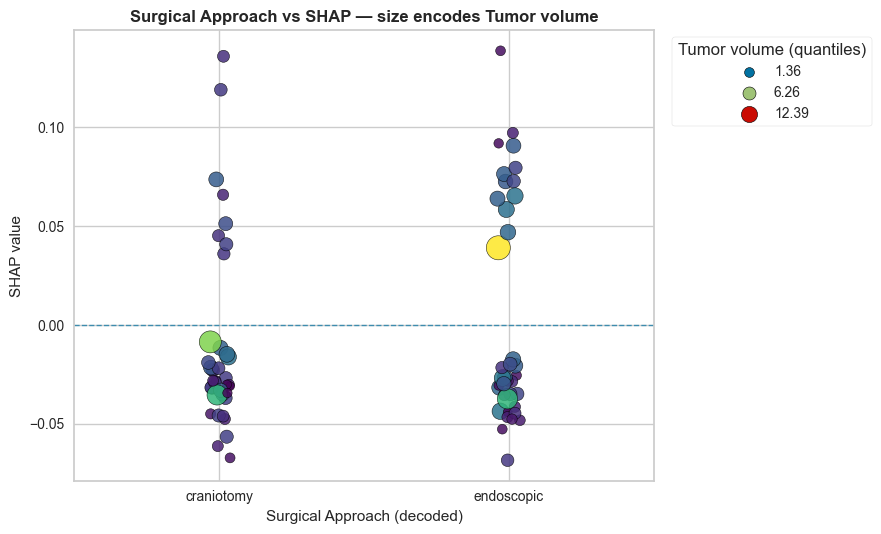

'xai_plots/shap_dep_approach_matplotlib.png'

In [27]:
# SHAP dependence (Matplotlib) with bubble SIZE = Tumor volume, no color scale.
# x-axis uses decoded labels; legend shows only size circles.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.api.types import is_numeric_dtype, is_categorical_dtype

os.makedirs("figures/xai", exist_ok=True)

def shap_dependence_matplotlib(
    shap_values: np.ndarray,
    X: pd.DataFrame,
    feature_x: str,                     # original (encoded) feature for SHAP lookup
    y_feature: str | None = None,       # SHAP(feature) on y (defaults to feature_x)
    x_display: pd.Series | None = None, # decoded labels for x-axis
    size_feature: str | None = None,    # numeric feature -> marker size
    title: str | None = None,
    filename: str = "figures/xai/shap_dep_matplotlib.png",
):
    # ---- Align SHAP columns to X (tolerate extra columns in X) ----
    n_shap_cols = 1 if shap_values.ndim == 1 else shap_values.shape[1]
    X_for_shap_cols = list(X.columns)[:n_shap_cols]
    shap_df = (pd.DataFrame({X_for_shap_cols[0]: shap_values})
               if shap_values.ndim == 1
               else pd.DataFrame(shap_values, columns=X_for_shap_cols))
    dfp = X.copy().reset_index(drop=True)

    # Helpers
    import re
    def _norm(s: str) -> str:
        return re.sub(r"[\W_]+", " ", str(s)).strip().lower()

    def _ohe_group_cols(base_name: str, cols: list[str]) -> list[str]:
        base_n = _norm(base_name)
        return [c for c in cols if "_" in c and _norm(c.rsplit("_",1)[0]) == base_n]

    def _group_shap_for_feature(name: str, shap_df_: pd.DataFrame) -> pd.Series:
        if name in shap_df_.columns:
            return shap_df_[name]
        group_cols = _ohe_group_cols(name, list(shap_df_.columns))
        if group_cols:
            return shap_df_[group_cols].sum(axis=1)
        nm = _norm(name)
        for c in shap_df_.columns:
            if _norm(c) == nm:
                return shap_df_[c]
        raise AssertionError(f"Could not map {name} to SHAP columns.")

    def _ensure_series(name: str | None, Xdf: pd.DataFrame) -> pd.Series | None:
        if name is None: return None
        if name in Xdf.columns: return Xdf[name].reset_index(drop=True)
        nm = _norm(name)
        for c in Xdf.columns:
            if _norm(c) == nm:
                return Xdf[c].reset_index(drop=True)
        raise KeyError(f"{name} not found in X.")

    # X-axis values (decoded if provided)
    x_vals = (pd.Series(x_display).reset_index(drop=True)
              if x_display is not None else _ensure_series(feature_x, dfp))
    # Y = SHAP(feature)
    y_feat = y_feature if y_feature is not None else feature_x
    y_vals = _group_shap_for_feature(y_feat, shap_df).reset_index(drop=True)

    # Size encoding
    if size_feature is not None:
        s_raw = _ensure_series(size_feature, dfp).astype(float)
        s_min, s_max = float(np.nanmin(s_raw)), float(np.nanmax(s_raw))
        if np.isclose(s_min, s_max):
            sizes = np.full(len(dfp), 80.0)
        else:
            sizes = 40.0 + 260.0 * (s_raw - s_min) / (s_max - s_min)   # 40..300
    else:
        sizes = np.full(len(dfp), 80.0)

    # ---- Plot ----
    fig, ax = plt.subplots(figsize=(9, 5.5))

    if is_numeric_dtype(x_vals):
        x_plot = x_vals.to_numpy()
        ax.set_xlabel(feature_x)
    else:
        if is_categorical_dtype(x_vals):
            cats = x_vals.cat
        else:
            cats = pd.Categorical(x_vals)
        x_num = cats.codes.astype(float)
        rng = np.random.default_rng(42)
        x_plot = x_num + (rng.random(len(x_num)) - 0.5) * 0.08  # tiny jitter
        ax.set_xticks(np.unique(x_num))
        ax.set_xticklabels(list(cats.categories))
        ax.set_xlim(-0.5, np.max(x_num) + 0.5)
        ax.set_xlabel(feature_x + (" (decoded)" if x_display is not None else ""))

    # Single-color points; no color scale
    from matplotlib.colors import Normalize
    norm = Normalize(vmin=float(np.nanmin(s_raw)), vmax=float(np.nanmax(s_raw)))

    # color by tumor volume (no colorbar added)
    ax.scatter(
        x_plot, y_vals,
        s=sizes,
        c=s_raw, cmap="viridis", norm=norm,   # <— color by volume
        alpha=0.85,
        edgecolors="black", linewidths=0.4
    )
    ax.axhline(0, linestyle="--", linewidth=1, alpha=0.7)
    ax.set_ylabel("SHAP value")
    ax.set_title(title or f"SHAP dependence: {feature_x}", fontweight="bold")

    # Size-only legend (quantiles)
    if size_feature is not None:
        q_vals = np.unique(np.round(np.nanquantile(s_raw, [0.1, 0.5, 0.9]), 2))
        handles, labels = [], []
        for q in q_vals:
            if np.isclose(s_min, s_max):
                sz = 80.0
            else:
                sz = 40.0 + 260.0 * (q - s_min) / (s_max - s_min)
            h = ax.scatter([], [], s=sz, edgecolors="black", linewidths=0.4)
            handles.append(h); labels.append(f"{q}")
        ax.legend(handles, labels, title=f"{size_feature} (quantiles)",
                  scatterpoints=1, frameon=True, loc="upper left", bbox_to_anchor=(1.02, 1.0))

    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    return filename

shap_dependence_matplotlib(
    shap_vals_kernel,
    X_explain_decoded,
    feature_x="Surgical Approach",
    y_feature="Surgical Approach",
    x_display=X_explain_decoded["Surgical Approach (decoded)"],
    size_feature="Tumor volume",
    title="Surgical Approach vs SHAP — size encodes Tumor volume",
    filename="figures/xai/shap_dep_approach_matplotlib.png"
)


In [28]:
# --- Decode the 3-level OHE for: "Resection outcome (total, subtotal, partial)" ---
import re
import numpy as np
import pandas as pd

def _norm(s: str) -> str:
    # normalize for tolerant matching
    return re.sub(r"[\W_]+", " ", str(s)).strip().lower()

def decode_ohe_to_single_series(base_name: str, X: pd.DataFrame) -> pd.Series:
    """
    Collapse one-hot columns for a categorical feature into a single categorical Series.
    Works even if punctuation/spacing differs between base and column names.
    """
    cols = []
    levels = []

    # 1) exact prefix match (preferred)
    prefix = base_name + "_"
    for c in X.columns:
        if c.startswith(prefix):
            cols.append(c)
            levels.append(c.split(prefix, 1)[1])

    # 2) tolerant match if nothing found
    if not cols:
        bn = _norm(base_name)
        for c in X.columns:
            cn = _norm(c)
            if cn.startswith(bn + " "):  # normalized "base + _"
                cols.append(c)
                # take original suffix after last "_"
                levels.append(c.split("_", 1)[1] if "_" in c else c)

    if not cols:
        raise KeyError(f"No OHE columns found for '{base_name}'")

    M = X[cols].to_numpy()
    idx = M.argmax(axis=1)
    labels = np.array(levels, dtype=object)[idx]
    labels[(M.sum(axis=1) == 0)] = np.nan  # rows with all zeros → NaN

    return pd.Series(pd.Categorical(labels, categories=levels),
                     name=base_name).reset_index(drop=True)

# Build decoded labels for plotting on x
# --- Decode the OHE columns for "Resection outcome" and reorder categories ---
resection_base = "Resection outcome (total subtotal partial)"

resection_decoded = decode_ohe_to_single_series(resection_base, X_explain_decoded)

# Force the x-axis order: subtotal → near total → total
desired_order = ["subtotal", "near total", "total"]

# Apply new ordered categories
resection_decoded = pd.Categorical(resection_decoded, categories=desired_order, ordered=True)
resection_decoded = pd.Series(resection_decoded, name=resection_base)

# --- SHAP dependence plot ---
shap_dependence_matplotlib(
    shap_vals_kernel,
    X_explain_decoded,
    feature_x=resection_base,        # base name for SHAP feature grouping
    y_feature=resection_base,        # y-axis SHAP from the same feature
    x_display=resection_decoded,     # decoded + ordered categories for x-axis
    size_feature="Tumor volume",     # bubble size = tumor volume
    title="Resection outcome vs SHAP — size encodes Tumor volume",
    filename="figures/xai/shap_dep_resection_matplotlib.png"
)


AssertionError: Could not map Resection outcome (total subtotal partial) to SHAP columns.

In [ ]:
X_explain.columns

Index(['Age ', 'BMI', 'Tumor size', 'Tumor size.1', 'Tumor size.2',
       'Tumor volume', 'Last BMI on file',
       'Pre-op visual impairment (y/n) - symptomatic complaint of visual loss',
       'Pre-op hydrocephalus (y/n)', 'Pre-op intacranial pressure symptoms',
       'Pre-op headache', 'Pre-op endocrine changes (y/n)',
       'Pre-op panhypopit (y/n) - define number of hormone axes that are non-functional',
       'Intraventricular extension', 'Surgical Approach',
       'Resection outcome (total subtotal partial)_total',
       'Resection outcome (total subtotal partial)_subtotal',
       'Resection outcome (total subtotal partial)_near total'],
      dtype='object')

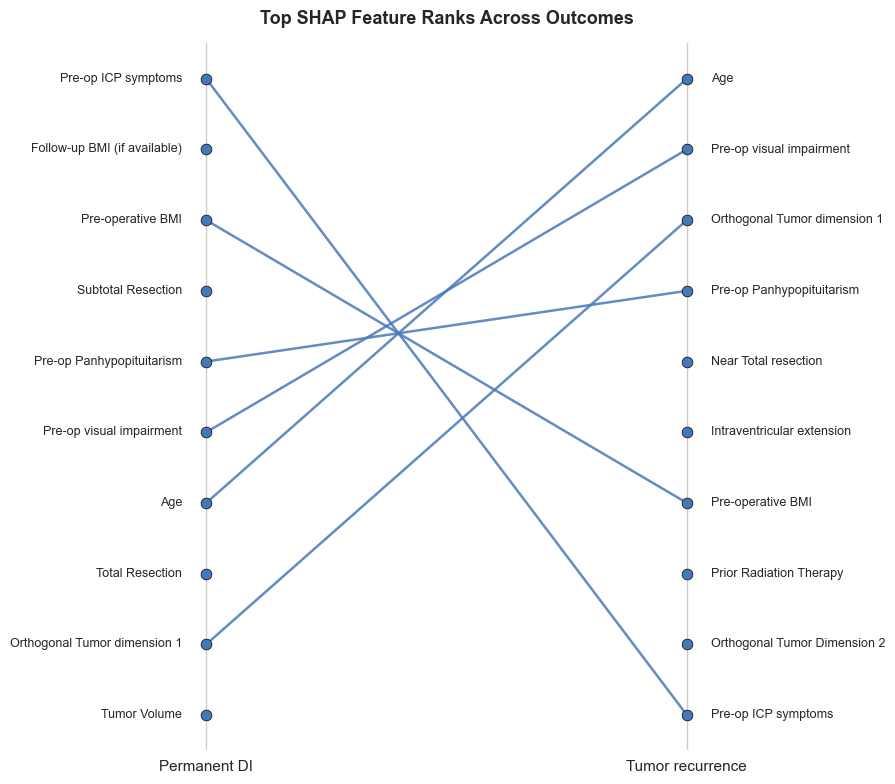

In [30]:
# Clean slopegraph comparing top SHAP features across outcomes.
# - Removes background grid and all axes except x-axis labels.
# - Does NOT draw lines for features unique to one target.
# - Saves to xai_plots/shap_rank_slope_clean.png (300 dpi).

import os
import matplotlib.pyplot as plt

os.makedirs("figures/xai", exist_ok=True)

# ---- Rank lists ----
perm_di = [
    "Pre-op ICP symptoms",
    "Follow-up BMI (if available)",
    "Pre-operative BMI",
    "Subtotal Resection",
    "Pre-op Panhypopituitarism",
    "Pre-op visual impairment",
    "Age",
    "Total Resection",
    "Orthogonal Tumor dimension 1",
    "Tumor Volume",
]

recurrence = [
    "Age", 
    "Pre-op visual impairment", 
    "Orthogonal Tumor dimension 1", 
    "Pre-op Panhypopituitarism",
    "Near Total resection", 
    "Intraventricular extension", 
    "Pre-operative BMI", 
    "Prior Radiation Therapy", 
    "Orthogonal Tumor Dimension 2", 
    "Pre-op ICP symptoms",
]

# ---- Build rank dictionaries ----
rank_left  = {feat: i+1 for i, feat in enumerate(perm_di)}
rank_right = {feat: i+1 for i, feat in enumerate(recurrence)}

# ---- Ordered union of features ----
shared      = [f for f in perm_di if f in rank_right]
left_only   = [f for f in perm_di if f not in rank_right]
right_only  = [f for f in recurrence if f not in rank_left]
ordered_features = shared + left_only + right_only

# ---- Plot ----
fig, ax = plt.subplots(figsize=(9, 8))
x_left, x_right = 0, 1
max_rank = max(len(perm_di), len(recurrence))
ax.set_xlim(-0.15, 1.15)
ax.set_ylim(max_rank + 0.5, 0.5)

# Styles
line_kw = dict(color="#4678b8", alpha=0.85, linewidth=1.8)
dot_kw  = dict(color="#4678b8", edgecolors="black", linewidths=0.5, s=60, zorder=3)

# ---- Draw ----
for feat in ordered_features:
    yL = rank_left.get(feat)
    yR = rank_right.get(feat)

    # Shared features → draw connecting line
    if (yL is not None) and (yR is not None):
        ax.plot([x_left, x_right], [yL, yR], **line_kw)
        ax.scatter([x_left], [yL], **dot_kw)
        ax.scatter([x_right], [yR], **dot_kw)

    # Left-only → marker only on left
    elif yL is not None and yR is None:
        ax.scatter([x_left], [yL], **dot_kw)

    # Right-only → marker only on right
    elif yR is not None and yL is None:
        ax.scatter([x_right], [yR], **dot_kw)

# ---- Add feature labels ----
for feat in ordered_features:
    if feat in rank_left:
        ax.text(x_left - 0.05, rank_left[feat], feat, ha="right", va="center", fontsize=9)
    if feat in rank_right:
        ax.text(x_right + 0.05, rank_right[feat], feat, ha="left", va="center", fontsize=9)

# ---- X-axis labels only ----
ax.set_xticks([x_left, x_right])
ax.set_xticklabels(["Permanent DI", "Tumor recurrence"], fontsize=11)

# ---- Clean look ----
ax.set_yticks([])
ax.set_ylabel("")
for spine in ["top", "right", "left", "bottom"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False, bottom=False)
ax.set_facecolor("white")

# ---- Title ----
ax.set_title("Top SHAP Feature Ranks Across Outcomes", fontsize=13, fontweight="bold", pad=14)

fig.tight_layout()
fig.savefig("figures/xai/shap_rank_slope.png", dpi=400, bbox_inches="tight")
plt.show()
